In [1]:
import sys
print(sys.executable)

c:\Users\KIIT0001\Documents\Multimodal-Skin-Lesion-Classification\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Original dataset location
DATASET_DIR = Path(
    r"C:\Users\KIIT0001\Documents\PAD-UFES-20"
)

METADATA_PATH = DATASET_DIR / "metadata.csv"
IMAGE_DIR = DATASET_DIR / "images"

# Load original metadata
df = pd.read_csv(METADATA_PATH)

print("Metadata loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Metadata loaded successfully!
Shape: (2298, 26)

Columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

First 5 records:


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


In [3]:
# 1. Dataset dimensions
print("Total records:", len(df))
print("Total columns:", len(df.columns))

# 2. Diagnostic distribution
print("\nDiagnostic distribution:")
print(df["diagnostic"].value_counts(dropna=False))

# 3. Unique identifiers
print("\nUnique patients:", df["patient_id"].nunique())
print("Unique lesion IDs:", df["lesion_id"].nunique())
print("Unique patient-lesion pairs:",
      df[["patient_id", "lesion_id"]].drop_duplicates().shape[0])
print("Unique image IDs:", df["img_id"].nunique())

# 4. Duplicate checks
print("\nDuplicate image IDs:", df["img_id"].duplicated().sum())

print("Duplicate patient-lesion-image records:",
      df.duplicated(
          subset=["patient_id", "lesion_id", "img_id"]
      ).sum())

# 5. Missing values
print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False))

Total records: 2298
Total columns: 26

Diagnostic distribution:
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

Unique patients: 1373
Unique lesion IDs: 1641
Unique patient-lesion pairs: 1891
Unique image IDs: 2298

Duplicate image IDs: 0
Duplicate patient-lesion-image records: 0

Missing values per column:
background_mother      822
background_father      818
pesticide              804
gender                 804
drink                  804
smoke                  804
skin_cancer_history    804
has_sewage_system      804
has_piped_water        804
cancer_history         804
diameter_1             804
diameter_2             804
fitspatrick            804
patient_id               0
age                      0
lesion_id                0
region                   0
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation     

In [4]:
# Complete missing-value report
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

print(missing_report.to_string())

                     Missing_Count  Missing_Percentage
background_mother              822               35.77
background_father              818               35.60
pesticide                      804               34.99
gender                         804               34.99
drink                          804               34.99
smoke                          804               34.99
skin_cancer_history            804               34.99
has_sewage_system              804               34.99
has_piped_water                804               34.99
cancer_history                 804               34.99
diameter_1                     804               34.99
diameter_2                     804               34.99
fitspatrick                    804               34.99
patient_id                       0                0.00
age                              0                0.00
lesion_id                        0                0.00
region                           0                0.00
diagnostic

In [5]:
# Records with missing values
print("Rows with at least one missing value:",
      df.isnull().any(axis=1).sum())

print("Rows with no missing values:",
      df.notnull().all(axis=1).sum())

Rows with at least one missing value: 824
Rows with no missing values: 1474


In [6]:
# Count missing values in each row
df["missing_count"] = df.isnull().sum(axis=1)

print("Missing values per row:")
print(df["missing_count"].value_counts().sort_index())

# Compare missingness with biopsy status
print("\nMissingness vs biopsy status:")

print(
    pd.crosstab(
        df["missing_count"] > 0,
        df["biopsed"],
        margins=True
    )
)

# Compare complete and incomplete records by diagnosis
print("\nMissingness vs diagnosis:")

print(
    pd.crosstab(
        df["diagnostic"],
        df["missing_count"] > 0,
        margins=True
    )
)

Missing values per row:
missing_count
0     1474
1        8
2       12
13     804
Name: count, dtype: int64

Missingness vs biopsy status:


biopsed        False  True   All
missing_count                   
False            132  1342  1474
True             824     0   824
All              956  1342  2298

Missingness vs diagnosis:
missing_count  False  True   All
diagnostic                      
ACK              273   457   730
BCC              845     0   845
MEL               52     0    52
NEV               72   172   244
SCC              192     0   192
SEK               40   195   235
All             1474   824  2298


In [7]:
clinical_candidates = [
    "age",
    "region",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation"
]

for col in clinical_candidates:
    print(f"\n{'='*40}")
    print(f"Feature: {col}")
    print(df[col].value_counts(dropna=False).to_string())


Feature: age
age
55    73
73    73
58    70
71    66
62    66
75    66
57    63
65    62
53    60
66    58
68    57
69    57
77    54
51    53
64    52
70    52
63    51
67    51
52    51
56    48
54    47
59    46
60    45
61    45
79    43
50    43
78    42
72    40
80    36
81    36
47    36
74    35
83    34
45    33
39    31
46    29
41    25
85    24
44    23
43    22
84    20
76    20
49    20
35    19
32    17
48    17
36    17
40    17
37    16
82    15
90    14
42    13
31    13
38    12
86    12
88    11
17    11
34    10
33     9
27     9
21     8
22     8
87     8
91     7
89     7
30     7
14     6
26     6
13     5
10     5
20     5
92     4
25     4
29     4
94     3
9      3
23     3
16     3
28     3
8      2
24     2
12     2
6      2
18     1

Feature: region
region
FACE       570
FOREARM    392
CHEST      280
BACK       248
ARM        192
NOSE       158
HAND       126
NECK        93
EAR         73
THIGH       73
ABDOMEN     36
LIP         23
SCALP       18
FOOT   

In [8]:
symptom_features = [
    "itch",
    "hurt",
    "bleed",
    "elevation"
]

for col in symptom_features:
    print(f"\n--- {col} vs biopsed ---")
    print(pd.crosstab(
        df[col],
        df["biopsed"],
        margins=True
    ))


--- itch vs biopsed ---
biopsed  False  True   All
itch                      
False      444   393   837
True       512   943  1455
UNK          0     6     6
All        956  1342  2298

--- hurt vs biopsed ---
biopsed  False  True   All
hurt                      
False      935   956  1891
True        21   376   397
UNK          0    10    10
All        956  1342  2298

--- bleed vs biopsed ---
biopsed  False  True   All
bleed                     
False      898   780  1678
True        58   556   614
UNK          0     6     6
All        956  1342  2298

--- elevation vs biopsed ---
biopsed    False  True   All
elevation                   
False        541   322   863
True         415  1018  1433
UNK            0     2     2
All          956  1342  2298


In [9]:
from PIL import Image
from collections import Counter
import os

image_dirs = [
    IMAGE_DIR / "imgs_part_1",
    IMAGE_DIR / "imgs_part_2",
    IMAGE_DIR / "imgs_part_3"
]

image_paths = []

for folder in image_dirs:
    image_paths.extend(folder.glob("*.png"))

print("Total image files:", len(image_paths))

corrupted_images = []
image_dimensions = Counter()

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_dimensions[img.size] += 1

    except Exception as e:
        corrupted_images.append((path.name, str(e)))

print("Corrupted images:", len(corrupted_images))
print("Unique image dimensions:", len(image_dimensions))

print("\nMost common dimensions:")
print(image_dimensions.most_common(10))

if corrupted_images:
    print("\nCorrupted image examples:")
    print(corrupted_images[:10])

Total image files: 2298
Corrupted images: 0
Unique image dimensions: 1450

Most common dimensions:
[((750, 750), 75), ((640, 640), 40), ((1242, 1242), 17), ((1125, 1125), 10), ((433, 433), 6), ((534, 534), 6), ((2268, 2268), 6), ((542, 542), 6), ((1145, 1145), 5), ((2176, 2176), 5)]


In [10]:
# Create a lookup of all image filenames
available_images = {
    path.name for path in image_paths
}

metadata_images = set(df["img_id"].astype(str))

# Compare metadata and actual image files
missing_images = metadata_images - available_images
extra_images = available_images - metadata_images

print("Images listed in metadata:", len(metadata_images))
print("Images found on disk:", len(available_images))
print("Metadata records without images:", len(missing_images))
print("Images without metadata records:", len(extra_images))

if missing_images:
    print("\nMissing image examples:", list(missing_images)[:10])

if extra_images:
    print("\nExtra image examples:", list(extra_images)[:10])

Images listed in metadata: 2298
Images found on disk: 2298
Metadata records without images: 0
Images without metadata records: 0


In [11]:
import hashlib
from collections import defaultdict
from tqdm import tqdm

hash_groups = defaultdict(list)

for path in tqdm(image_paths, desc="Hashing images"):
    with open(path, "rb") as f:
        image_hash = hashlib.md5(f.read()).hexdigest()

    hash_groups[image_hash].append(path.name)

duplicate_groups = [
    filenames
    for filenames in hash_groups.values()
    if len(filenames) > 1
]

print("Unique image contents:", len(hash_groups))
print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Images involved in duplicate groups:",
    sum(len(group) for group in duplicate_groups)
)

for group in duplicate_groups:
    print(group)

Hashing images: 100%|██████████| 2298/2298 [00:14<00:00, 155.00it/s]

Unique image contents: 2283
Exact duplicate groups: 15
Images involved in duplicate groups: 30
['PAT_202_307_424.png', 'PAT_202_308_721.png']
['PAT_302_650_477.png', 'PAT_302_651_529.png']
['PAT_311_666_191.png', 'PAT_311_667_416.png']
['PAT_38_1002_34.png', 'PAT_38_1003_68.png']
['PAT_38_1002_668.png', 'PAT_38_1003_226.png']
['PAT_419_2767_323.png', 'PAT_419_833_148.png']
['PAT_528_3072_615.png', 'PAT_528_993_589.png']
['PAT_56_86_479.png', 'PAT_56_88_274.png']
['PAT_570_1084_637.png', 'PAT_570_1085_344.png']
['PAT_570_1084_939.png', 'PAT_570_1085_429.png']
['PAT_691_1311_2.png', 'PAT_691_3994_671.png']
['PAT_691_1311_890.png', 'PAT_691_3994_791.png']
['PAT_701_1321_156.png', 'PAT_701_4056_457.png']
['PAT_759_1433_914.png', 'PAT_759_1538_566.png']
['PAT_834_1572_430.png', 'PAT_834_1574_276.png']


In [12]:
# Inspect duplicate groups against original metadata

for i, group in enumerate(duplicate_groups, start=1):

    records = df[df["img_id"].isin(group)][
        ["patient_id", "lesion_id", "img_id", "diagnostic", "biopsed"]
    ]

    print(f"\n{'='*60}")
    print(f"Duplicate Group {i}")
    display(records)

    print(
        "Same diagnosis:",
        records["diagnostic"].nunique() == 1
    )

    print(
        "Same patient:",
        records["patient_id"].nunique() == 1
    )


Duplicate Group 1


,patient_id,lesion_id,img_id,diagnostic,biopsed
606,PAT_202,307,PAT_202_307_424.png,BCC,True
2211,PAT_202,308,PAT_202_308_721.png,ACK,True


Same diagnosis: False
Same patient: True

Duplicate Group 2


,patient_id,lesion_id,img_id,diagnostic,biopsed
28,PAT_302,651,PAT_302_651_529.png,BCC,True
1753,PAT_302,650,PAT_302_650_477.png,SCC,True


Same diagnosis: False
Same patient: True

Duplicate Group 3


,patient_id,lesion_id,img_id,diagnostic,biopsed
726,PAT_311,666,PAT_311_666_191.png,SCC,True
1632,PAT_311,667,PAT_311_667_416.png,BCC,True


... (21 outputs left out)

,patient_id,lesion_id,img_id,diagnostic,biopsed
18,PAT_759,1538,PAT_759_1538_566.png,BCC,True
888,PAT_759,1433,PAT_759_1433_914.png,NEV,True


Same diagnosis: False
Same patient: True

Duplicate Group 15


,patient_id,lesion_id,img_id,diagnostic,biopsed
1139,PAT_834,1574,PAT_834_1574_276.png,SCC,True
1982,PAT_834,1572,PAT_834_1572_430.png,SCC,True


Same diagnosis: True
Same patient: True


In [13]:
# Identify conflicting and same-label duplicate groups

conflicting_groups = []
same_label_groups = []

for group in duplicate_groups:
    records = df[df["img_id"].isin(group)]

    if records["diagnostic"].nunique() > 1:
        conflicting_groups.append(group)
    else:
        same_label_groups.append(group)

conflicting_records = sum(
    len(group) for group in conflicting_groups
)

same_label_records = sum(
    len(group) for group in same_label_groups
)

redundant_same_label_records = sum(
    len(group) - 1 for group in same_label_groups
)

total_excluded = (
    conflicting_records + redundant_same_label_records
)

print("Conflicting groups:", len(conflicting_groups))
print("Records in conflicting groups:", conflicting_records)

print("\nSame-label groups:", len(same_label_groups))
print("Records in same-label groups:", same_label_records)
print("Redundant records in same-label groups:",
      redundant_same_label_records)

print("\nTotal proposed exclusions:", total_excluded)
print("Records remaining:", len(df) - total_excluded)

Conflicting groups: 12
Records in conflicting groups: 24

Same-label groups: 3
Records in same-label groups: 6
Redundant records in same-label groups: 3

Total proposed exclusions: 27
Records remaining: 2271


In [14]:
audit_records = []

for group in duplicate_groups:
    records = df[df["img_id"].isin(group)].copy()

    if records["diagnostic"].nunique() > 1:
        records["action"] = "EXCLUDE - conflicting diagnosis"

    else:
        # Prefer biopsy-confirmed record when available
        records = records.sort_values(
            "biopsed", ascending=False
        )
        records["action"] = "EXCLUDE - redundant image"
        records.iloc[0, records.columns.get_loc("action")] = (
            "KEEP - representative image"
        )

    for _, row in records.iterrows():
        audit_records.append({
            "img_id": row["img_id"],
            "patient_id": row["patient_id"],
            "lesion_id": row["lesion_id"],
            "diagnostic": row["diagnostic"],
            "biopsed": row["biopsed"],
            "action": row["action"]
        })

duplicate_audit = pd.DataFrame(audit_records)
display(duplicate_audit)

,img_id,patient_id,lesion_id,diagnostic,biopsed,action
0,PAT_202_307_424.png,PAT_202,307,BCC,True,EXCLUDE - conflicting diagnosis
1,PAT_202_308_721.png,PAT_202,308,ACK,True,EXCLUDE - conflicting diagnosis
2,PAT_302_651_529.png,PAT_302,651,BCC,True,EXCLUDE - conflicting diagnosis
3,PAT_302_650_477.png,PAT_302,650,SCC,True,EXCLUDE - conflicting diagnosis
4,PAT_311_666_191.png,PAT_311,666,SCC,True,EXCLUDE - conflicting diagnosis
5,PAT_311_667_416.png,PAT_311,667,BCC,True,EXCLUDE - conflicting diagnosis
6,PAT_38_1002_34.png,PAT_38,1002,BCC,True,EXCLUDE - conflicting diagnosis
7,PAT_38_1003_68.png,PAT_38,1003,ACK,True,EXCLUDE - conflicting diagnosis
8,PAT_38_1003_226.png,PAT_38,1003,ACK,True,EXCLUDE - conflicting diagnosis
9,PAT_38_1002_668.png,PAT_38,1002,BCC,True,EXCLUDE - conflicting diagnosis


In [15]:
# Get IDs marked for exclusion
excluded_ids = duplicate_audit.loc[
    duplicate_audit["action"].str.startswith("EXCLUDE"),
    "img_id"
]

# Create a separate cleaned dataframe
df_clean = df[~df["img_id"].isin(excluded_ids)].copy()

# Verify
print("Original records:", len(df))
print("Excluded records:", len(excluded_ids))
print("Remaining records:", len(df_clean))
print("Duplicate image IDs:", df_clean["img_id"].duplicated().sum())

Original records: 2298
Excluded records: 27
Remaining records: 2271
Duplicate image IDs: 0


In [16]:
# Map the original six diagnoses into three classes
diagnosis_mapping = {
    "BCC": "Malignant",
    "SCC": "Malignant",
    "MEL": "Malignant",
    "ACK": "Precancerous",
    "NEV": "Benign",
    "SEK": "Benign"
}

# Create a new target column
df_clean["target"] = df_clean["diagnostic"].map(diagnosis_mapping)

# Check class distribution
print("Three-class distribution:")
print(df_clean["target"].value_counts())

print("\nClass distribution (%):")
print(
    (df_clean["target"].value_counts(normalize=True) * 100)
    .round(2)
)

Three-class distribution:
target
Malignant       1071
Precancerous     723
Benign           477
Name: count, dtype: int64

Class distribution (%):
target
Malignant       47.16
Precancerous    31.84
Benign          21.00
Name: proportion, dtype: float64


In [17]:
print("Total records:", len(df_clean))
print("Unique patients:", df_clean["patient_id"].nunique())

print("\nRecords per patient:")
print(df_clean.groupby("patient_id").size().describe())

Total records: 2271
Unique patients: 1371

Records per patient:
count    1371.000000
mean        1.656455
std         1.089160
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
dtype: float64


In [18]:
# Number of distinct target classes per patient
patient_class_counts = (
    df_clean.groupby("patient_id")["target"].nunique()
)

print("Patients with only one target class:",
      (patient_class_counts == 1).sum())

print("Patients with multiple target classes:",
      (patient_class_counts > 1).sum())

Patients with only one target class: 1232
Patients with multiple target classes: 139


In [19]:
# Find patients having multiple target classes
multi_class_patients = patient_class_counts[
    patient_class_counts > 1
]

print("Patients with multiple classes:",
      len(multi_class_patients))

print("\nNumber of classes per patient:")
print(multi_class_patients.value_counts().sort_index())

Patients with multiple classes: 139

Number of classes per patient:
target
2    134
3      5
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import StratifiedGroupKFold

# Create 20 patient-grouped folds
sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=42
)

# Assign a fold number to every record
fold_ids = np.full(len(df_clean), -1)

for fold, (_, test_idx) in enumerate(
    sgkf.split(
        df_clean,
        y=df_clean["target"],
        groups=df_clean["patient_id"]
    )
):
    fold_ids[test_idx] = fold

# Combine folds into three datasets
df_clean["split"] = np.where(
    fold_ids < 14, "train",
    np.where(fold_ids < 17, "validation", "test")
)

# Check record counts
print("Records in each split:")
print(df_clean["split"].value_counts())

# Check class distribution
print("\nClass distribution in each split:")
print(pd.crosstab(
    df_clean["split"],
    df_clean["target"],
    normalize="index"
).round(3) * 100)

Records in each split:
split
train         1602
validation     359
test           310
Name: count, dtype: int64

Class distribution in each split:
target      Benign  Malignant  Precancerous
split                                      
test          18.7       51.9          29.4
train         21.0       47.6          31.4
validation    23.1       40.9          35.9


In [21]:
# Get unique patient IDs in each split
train_patients = set(
    df_clean[df_clean["split"] == "train"]["patient_id"]
)

val_patients = set(
    df_clean[df_clean["split"] == "validation"]["patient_id"]
)

test_patients = set(
    df_clean[df_clean["split"] == "test"]["patient_id"]
)

# Check overlap
print("Train-Validation overlap:", len(train_patients & val_patients))
print("Train-Test overlap:", len(train_patients & test_patients))
print("Validation-Test overlap:", len(val_patients & test_patients))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [22]:
from pathlib import Path

OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    OUTPUT_DIR / "cleaned_metadata_with_splits.csv",
    index=False
)

print("Dataset split saved successfully!")

Dataset split saved successfully!


In [23]:
from sklearn.model_selection import StratifiedGroupKFold

best_score = float("inf")
best_split = None
best_seed = None

for seed in range(50):

    sgkf = StratifiedGroupKFold(
        n_splits=20,
        shuffle=True,
        random_state=seed
    )

    fold_ids = np.full(len(df_clean), -1)

    for fold, (_, test_idx) in enumerate(
        sgkf.split(
            df_clean,
            y=df_clean["target"],
            groups=df_clean["patient_id"]
        )
    ):
        fold_ids[test_idx] = fold

    candidate = np.where(
        fold_ids < 14, "train",
        np.where(fold_ids < 17, "validation", "test")
    )

    temp = df_clean[["target"]].copy()
    temp["split"] = candidate

    # Difference from desired split proportions
    sizes = temp["split"].value_counts(normalize=True)
    size_error = sum(
        (sizes.get(s, 0) - desired) ** 2
        for s, desired in [
            ("train", 0.70),
            ("validation", 0.15),
            ("test", 0.15)
        ]
    )

    # Difference from original class proportions
    proportions = pd.crosstab(
        temp["split"],
        temp["target"],
        normalize="index"
    )

    original = df_clean["target"].value_counts(normalize=True)

    class_error = sum(
        (proportions.loc[s, c] - original[c]) ** 2
        for s in ["train", "validation", "test"]
        for c in original.index
    )

    score = size_error + class_error

    if score < best_score:
        best_score = score
        best_split = candidate.copy()
        best_seed = seed

print("Best random seed:", best_seed)
print("Best score:", best_score)

Best random seed: 19
Best score: 0.0006087954466011679


In [24]:
# Create a comparison dataframe without changing df_clean
comparison = df_clean[["target", "patient_id", "split"]].copy()
comparison["new_split"] = best_split

print("NEW SPLIT - Record counts:")
print(comparison["new_split"].value_counts())

print("\nNEW SPLIT - Class distribution (%):")
print(
    pd.crosstab(
        comparison["new_split"],
        comparison["target"],
        normalize="index"
    ).round(4) * 100
)

# Verify patient-level separation
patient_sets = {
    s: set(comparison.loc[
        comparison["new_split"] == s, "patient_id"
    ])
    for s in ["train", "validation", "test"]
}

print("\nPatient overlap:")
print("Train-Validation:", len(patient_sets["train"] & patient_sets["validation"]))
print("Train-Test:", len(patient_sets["train"] & patient_sets["test"]))
print("Validation-Test:", len(patient_sets["validation"] & patient_sets["test"]))

NEW SPLIT - Record counts:
new_split
train         1608
test           358
validation     305
Name: count, dtype: int64

NEW SPLIT - Class distribution (%):
target      Benign  Malignant  Precancerous
new_split                                  
test         20.95      48.04         31.01
train        21.14      46.95         31.90
validation   20.33      47.21         32.46

Patient overlap:
Train-Validation: 0
Train-Test: 0
Validation-Test: 0


In [25]:
df_clean["split"] = best_split

print("Final split distribution:")
print(df_clean["split"].value_counts())

# Save final metadata
OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    OUTPUT_DIR / "cleaned_metadata_with_splits.csv",
    index=False
)

print("\nFinal split saved successfully!")

Final split distribution:
split
train         1608
test           358
validation     305
Name: count, dtype: int64

Final split saved successfully!


In [26]:
clinical_features = [
    "age",
    "region",
    "itch",
    "hurt",
    "bleed",
    "elevation"
]

# Create a separate clinical dataframe
clinical_df = df_clean[
    clinical_features + ["target", "patient_id", "split"]
].copy()

# Inspect data types
print("Data types:")
print(clinical_df[clinical_features].dtypes)

# Check missing values
print("\nMissing values:")
print(clinical_df[clinical_features].isnull().sum())

# Check unique values
print("\nUnique values:")
for col in clinical_features:
    print(f"\n{col}:")
    print(clinical_df[col].value_counts(dropna=False))

Data types:
age           int64
region       object
itch         object
hurt         object
bleed        object
elevation    object
dtype: object

Missing values:
age          0
region       0
itch         0
hurt         0
bleed        0
elevation    0
dtype: int64

Unique values:

age:
age
55    73
73    73
58    70
71    66
62    66
      ..
8      2
24     2
12     2
6      2
18     1
Name: count, Length: 84, dtype: int64

region:
region
FACE       562
FOREARM    384
CHEST      279
BACK       247
ARM        189
NOSE       155
HAND       125
NECK        93
THIGH       73
EAR         71
ABDOMEN     36
LIP         23
SCALP       18
FOOT        16
Name: count, dtype: int64

itch:
itch
True     1435
False     830
UNK         6
Name: count, dtype: int64

hurt:
hurt
False    1870
True      391
UNK        10
Name: count, dtype: int64

bleed:
bleed
False    1664
True      601
UNK         6
Name: count, dtype: int64

elevation:
elevation
True     1410
False     859
UNK         2
Name: count, 

Age statistics:
count    2271.000000
mean       60.437252
std        15.931500
min         6.000000
25%        51.000000
50%        62.000000
75%        72.000000
max        94.000000
Name: age, dtype: float64


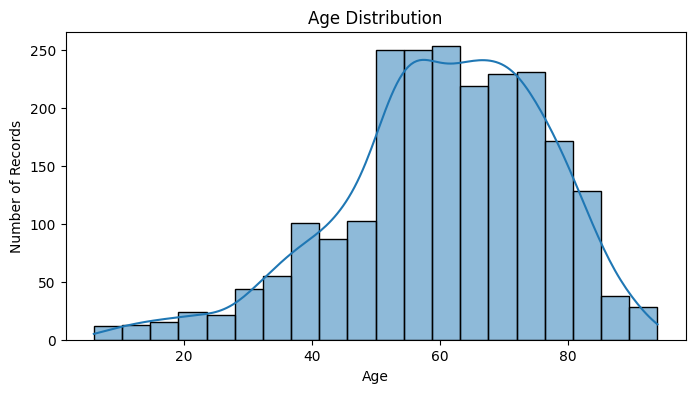

In [27]:
print("Age statistics:")
print(clinical_df["age"].describe())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(clinical_df["age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.show()

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical features
numerical_features = ["age"]

categorical_features = [
    "region", "itch", "hurt", "bleed", "elevation"
]

# Define preprocessing
clinical_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Prepare data according to the final split
X_train = df_clean.loc[
    df_clean["split"] == "train", clinical_features
]

X_val = df_clean.loc[
    df_clean["split"] == "validation", clinical_features
]

X_test = df_clean.loc[
    df_clean["split"] == "test", clinical_features
]

# Fit only on training data
X_train_processed = clinical_preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = clinical_preprocessor.transform(X_val)
X_test_processed = clinical_preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (1608, 27)
Validation shape: (305, 27)
Testing shape: (358, 27)


In [29]:
# Prepare target labels using the same split indices
y_train = df_clean.loc[X_train.index, "target"]
y_val = df_clean.loc[X_val.index, "target"]
y_test = df_clean.loc[X_test.index, "target"]

print("Training labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

print("\nInput-target alignment:")
print("Train:", X_train_processed.shape[0] == len(y_train))
print("Validation:", X_val_processed.shape[0] == len(y_val))
print("Test:", X_test_processed.shape[0] == len(y_test))

Training labels:
target
Malignant       755
Precancerous    513
Benign          340
Name: count, dtype: int64

Validation labels:
target
Malignant       144
Precancerous     99
Benign           62
Name: count, dtype: int64

Testing labels:
target
Malignant       172
Precancerous    111
Benign           75
Name: count, dtype: int64

Input-target alignment:
Train: True
Validation: True
Test: True


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Model 1: Logistic Regression
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

lr_predictions = lr_model.predict(X_val_processed)


# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_val_processed)


# Compare validation performance
print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_val, lr_predictions))
print("Macro F1:", f1_score(y_val, lr_predictions, average="macro"))
print(classification_report(y_val, lr_predictions))


print("\nRANDOM FOREST")
print("Accuracy:", accuracy_score(y_val, rf_predictions))
print("Macro F1:", f1_score(y_val, rf_predictions, average="macro"))
print(classification_report(y_val, rf_predictions))

LOGISTIC REGRESSION
Accuracy: 0.7114754098360656
Macro F1: 0.7008840819543553
              precision    recall  f1-score   support

      Benign       0.53      0.74      0.62        62
   Malignant       0.83      0.66      0.74       144
Precancerous       0.73      0.77      0.75        99

    accuracy                           0.71       305
   macro avg       0.70      0.72      0.70       305
weighted avg       0.74      0.71      0.72       305


RANDOM FOREST
Accuracy: 0.7114754098360656
Macro F1: 0.7043663380329565
              precision    recall  f1-score   support

      Benign       0.61      0.71      0.66        62
   Malignant       0.77      0.67      0.72       144
Precancerous       0.71      0.77      0.74        99

    accuracy                           0.71       305
   macro avg       0.70      0.72      0.70       305
weighted avg       0.72      0.71      0.71       305



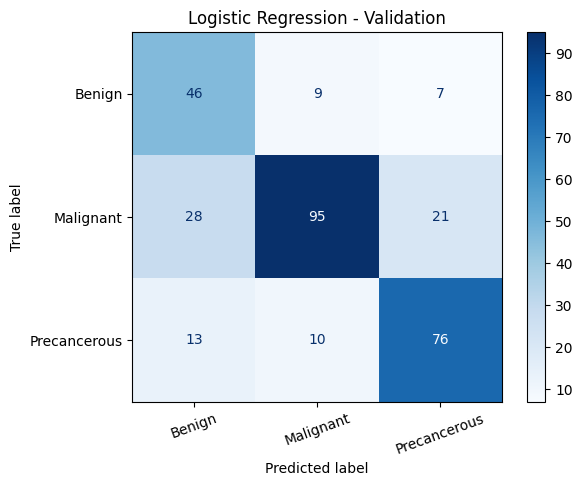

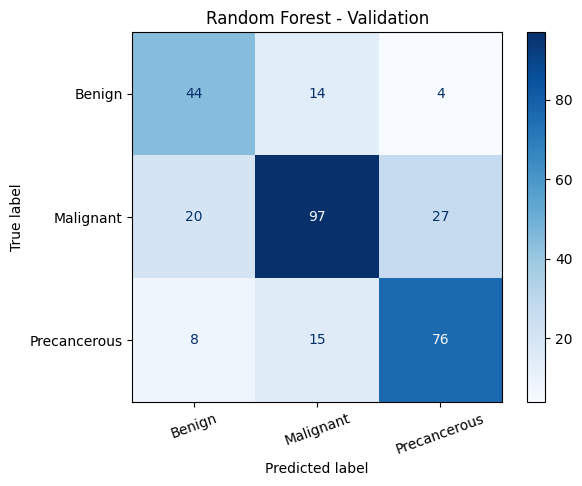

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = ["Benign", "Malignant", "Precancerous"]

# Logistic Regression
cm_lr = confusion_matrix(
    y_val, lr_predictions, labels=class_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Validation")
plt.xticks(rotation=20)
plt.show()


# Random Forest
cm_rf = confusion_matrix(
    y_val, rf_predictions, labels=class_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Validation")
plt.xticks(rotation=20)
plt.show()

In [32]:
baseline_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_val, lr_predictions),
        accuracy_score(y_val, rf_predictions)
    ],
    "Macro_F1": [
        f1_score(y_val, lr_predictions, average="macro"),
        f1_score(y_val, rf_predictions, average="macro")
    ]
})

print(baseline_results)

baseline_results.to_csv(
    "../results/metrics/clinical_baseline_results.csv",
    index=False
)

print("\nBaseline results saved successfully!")

                 Model  Accuracy  Macro_F1
0  Logistic Regression  0.711475  0.700884
1        Random Forest  0.711475  0.704366

Baseline results saved successfully!


In [33]:
from sklearn.svm import SVC

# Train SVM
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

# Validation predictions
svm_predictions = svm_model.predict(X_val_processed)

# Evaluate
print("SVM - RBF")
print("Accuracy:", accuracy_score(y_val, svm_predictions))
print("Macro F1:", f1_score(y_val, svm_predictions, average="macro"))

print(classification_report(y_val, svm_predictions))

SVM - RBF
Accuracy: 0.7344262295081967
Macro F1: 0.7264766501703251
              precision    recall  f1-score   support

      Benign       0.61      0.74      0.67        62
   Malignant       0.85      0.65      0.74       144
Precancerous       0.71      0.85      0.77        99

    accuracy                           0.73       305
   macro avg       0.72      0.75      0.73       305
weighted avg       0.75      0.73      0.73       305



In [34]:
clinical_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM (RBF)"
    ],
    "Accuracy": [
        accuracy_score(y_val, lr_predictions),
        accuracy_score(y_val, rf_predictions),
        accuracy_score(y_val, svm_predictions)
    ],
    "Macro_F1": [
        f1_score(y_val, lr_predictions, average="macro"),
        f1_score(y_val, rf_predictions, average="macro"),
        f1_score(y_val, svm_predictions, average="macro")
    ]
})

print(clinical_results)

clinical_results.to_csv(
    "../results/metrics/clinical_baseline_results.csv",
    index=False
)

print("\nUpdated clinical results saved!")

                 Model  Accuracy  Macro_F1
0  Logistic Regression  0.711475  0.700884
1        Random Forest  0.711475  0.704366
2            SVM (RBF)  0.734426  0.726477

Updated clinical results saved!


In [35]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Convert class names into numeric labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train_encoded)

# Predict validation labels
xgb_predictions_encoded = xgb_model.predict(X_val_processed)
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

# Evaluate
print("XGBoost")
print("Accuracy:", accuracy_score(y_val, xgb_predictions))
print("Macro F1:", f1_score(y_val, xgb_predictions, average="macro"))

print(classification_report(y_val, xgb_predictions))

XGBoost
Accuracy: 0.7278688524590164
Macro F1: 0.6960329390235932
              precision    recall  f1-score   support

      Benign       0.62      0.48      0.55        62
   Malignant       0.75      0.74      0.75       144
Precancerous       0.74      0.86      0.79        99

    accuracy                           0.73       305
   macro avg       0.71      0.70      0.70       305
weighted avg       0.72      0.73      0.72       305



In [36]:
clinical_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM (RBF)",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_val, lr_predictions),
        accuracy_score(y_val, rf_predictions),
        accuracy_score(y_val, svm_predictions),
        accuracy_score(y_val, xgb_predictions)
    ],
    "Macro_F1": [
        f1_score(y_val, lr_predictions, average="macro"),
        f1_score(y_val, rf_predictions, average="macro"),
        f1_score(y_val, svm_predictions, average="macro"),
        f1_score(y_val, xgb_predictions, average="macro")
    ],
    "Malignant_Recall": [
        classification_report(
            y_val, lr_predictions, output_dict=True
        )["Malignant"]["recall"],
        classification_report(
            y_val, rf_predictions, output_dict=True
        )["Malignant"]["recall"],
        classification_report(
            y_val, svm_predictions, output_dict=True
        )["Malignant"]["recall"],
        classification_report(
            y_val, xgb_predictions, output_dict=True
        )["Malignant"]["recall"]
    ]
})

print(clinical_results.round(4))

clinical_results.to_csv(
    "../results/metrics/clinical_baseline_results.csv",
    index=False
)

print("\nAll four model results saved successfully!")

                 Model  Accuracy  Macro_F1  Malignant_Recall
0  Logistic Regression    0.7115    0.7009            0.6597
1        Random Forest    0.7115    0.7044            0.6736
2            SVM (RBF)    0.7344    0.7265            0.6528
3              XGBoost    0.7279    0.6960            0.7431

All four model results saved successfully!


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.svm import SVC

# Build preprocessing and SVM into one pipeline
svm_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("num", StandardScaler(), ["age"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["region", "itch", "hurt", "bleed", "elevation"])
    ])),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

# Hyperparameter combinations
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1, 1]
}

# Patient-grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best combination
svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

groups_train = df_clean.loc[X_train.index, "patient_id"]

svm_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best parameters:")
print(svm_search.best_params_)

print("\nBest cross-validation Macro-F1:")
print(svm_search.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters:
{'classifier__C': 100, 'classifier__gamma': 0.01}

Best cross-validation Macro-F1:
0.7143802686202496


In [38]:
# Get the best tuned SVM pipeline
best_svm_model = svm_search.best_estimator_

# Predict on the validation set
tuned_svm_predictions = best_svm_model.predict(X_val)

# Evaluate
print("TUNED SVM - VALIDATION RESULTS")

print("Accuracy:",
      accuracy_score(y_val, tuned_svm_predictions))

print("Macro F1:",
      f1_score(y_val, tuned_svm_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, tuned_svm_predictions))

TUNED SVM - VALIDATION RESULTS
Accuracy: 0.7180327868852459
Macro F1: 0.7067410766040902

Classification Report:
              precision    recall  f1-score   support

      Benign       0.60      0.68      0.64        62
   Malignant       0.82      0.65      0.73       144
Precancerous       0.69      0.84      0.76        99

    accuracy                           0.72       305
   macro avg       0.70      0.72      0.71       305
weighted avg       0.73      0.72      0.72       305



In [39]:
svm_tuning_results = pd.DataFrame({
    "Model": ["SVM Original", "SVM Tuned"],
    "Accuracy": [
        accuracy_score(y_val, svm_predictions),
        accuracy_score(y_val, tuned_svm_predictions)
    ],
    "Macro_F1": [
        f1_score(y_val, svm_predictions, average="macro"),
        f1_score(y_val, tuned_svm_predictions, average="macro")
    ]
})

print(svm_tuning_results)

svm_tuning_results.to_csv(
    "../results/metrics/svm_tuning_comparison.csv",
    index=False
)

          Model  Accuracy  Macro_F1
0  SVM Original  0.734426  0.726477
1     SVM Tuned  0.718033  0.706741


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBClassifier

# Preprocessing pipeline
xgb_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), ["age"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     ["region", "itch", "hurt", "bleed", "elevation"])
])

# Complete pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter combinations
xgb_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.03, 0.05, 0.1]
}

# Patient-grouped cross-validation
xgb_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="f1_macro",
    cv=xgb_cv,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
xgb_search.fit(
    X_train,
    y_train_encoded,
    groups=groups_train
)

print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest cross-validation Macro-F1:")
print(xgb_search.best_score_)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}

Best cross-validation Macro-F1:
0.7191901425401173


In [41]:
# Get best tuned XGBoost pipeline
best_xgb_model = xgb_search.best_estimator_

# Predict on validation data
tuned_xgb_predictions_encoded = best_xgb_model.predict(X_val)

# Convert numeric predictions back to class names
tuned_xgb_predictions = label_encoder.inverse_transform(
    tuned_xgb_predictions_encoded.astype(int)
)

# Evaluate
print("TUNED XGBOOST - VALIDATION RESULTS")

print("Accuracy:",
      accuracy_score(y_val, tuned_xgb_predictions))

print("Macro F1:",
      f1_score(y_val, tuned_xgb_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, tuned_xgb_predictions))

TUNED XGBOOST - VALIDATION RESULTS
Accuracy: 0.7311475409836066
Macro F1: 0.6995703587370897

Classification Report:
              precision    recall  f1-score   support

      Benign       0.67      0.48      0.56        62
   Malignant       0.75      0.76      0.76       144
Precancerous       0.73      0.84      0.78        99

    accuracy                           0.73       305
   macro avg       0.72      0.70      0.70       305
weighted avg       0.73      0.73      0.73       305



In [42]:
xgb_tuning_results = pd.DataFrame({
    "Model": ["XGBoost Original", "XGBoost Tuned"],
    "Accuracy": [
        accuracy_score(y_val, xgb_predictions),
        accuracy_score(y_val, tuned_xgb_predictions)
    ],
    "Macro_F1": [
        f1_score(y_val, xgb_predictions, average="macro"),
        f1_score(y_val, tuned_xgb_predictions, average="macro")
    ],
    "Malignant_Recall": [
        classification_report(
            y_val, xgb_predictions, output_dict=True
        )["Malignant"]["recall"],
        classification_report(
            y_val, tuned_xgb_predictions, output_dict=True
        )["Malignant"]["recall"]
    ]
})

print(xgb_tuning_results.round(4))

xgb_tuning_results.to_csv(
    "../results/metrics/xgboost_tuning_comparison.csv",
    index=False
)

              Model  Accuracy  Macro_F1  Malignant_Recall
0  XGBoost Original    0.7279    0.6960            0.7431
1     XGBoost Tuned    0.7311    0.6996            0.7639


In [43]:
# Create a lookup dictionary for all image files
image_lookup = {}

for folder in image_dirs:
    for image_path in folder.glob("*.png"):
        image_lookup[image_path.name] = str(image_path)

# Add image paths to cleaned metadata
df_clean["image_path"] = df_clean["img_id"].map(image_lookup)

# Verify image paths
print("Total records:", len(df_clean))

print("Matched images:",
      df_clean["image_path"].notna().sum())

print("Missing images:",
      df_clean["image_path"].isna().sum())

print("\nRecords in each split:")
print(df_clean["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(df_clean["split"], df_clean["target"]))

Total records: 2271
Matched images: 2271
Missing images: 0

Records in each split:
split
train         1608
test           358
validation     305
Name: count, dtype: int64

Class distribution:
target      Benign  Malignant  Precancerous
split                                      
test            75        172           111
train          340        755           513
validation      62        144            99


In [44]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/interim/cleaned_metadata_with_splits.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nClinical features:")
clinical_features = [
    "age", "region", "itch", "hurt", "bleed", "elevation"
]

print(clinical_features)

Dataset shape: (2271, 29)

Split distribution:
split
train         1608
test           358
validation     305
Name: count, dtype: int64

Clinical features:
['age', 'region', 'itch', 'hurt', 'bleed', 'elevation']


In [45]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

X_train = train_df[clinical_features]
X_val = val_df[clinical_features]
X_test = test_df[clinical_features]

y_train = train_df["target"]
y_val = val_df["target"]
y_test = test_df["target"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1608, 6) (1608,)
Validation: (305, 6) (305,)
Testing: (358, 6) (358,)


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

numerical_features = ["age"]

categorical_features = [
    "region", "itch", "hurt", "bleed", "elevation"
]

clinical_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Clinical preprocessing pipeline defined.")

Clinical preprocessing pipeline defined.


In [47]:
clinical_svm = Pipeline(steps=[
    ("preprocessor", clinical_preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

print("Clinical SVM pipeline created.")

Clinical SVM pipeline created.


In [48]:
clinical_svm.fit(X_train, y_train)

print("Clinical SVM trained successfully.")
print("Training samples:", len(X_train))
print("Features used:", clinical_features)

Clinical SVM trained successfully.
Training samples: 1608
Features used: ['age', 'region', 'itch', 'hurt', 'bleed', 'elevation']


In [49]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models/clinical")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    clinical_svm,
    MODEL_DIR / "best_clinical_svm.pkl"
)

print("Clinical SVM saved successfully.")
print("Path:", MODEL_DIR / "best_clinical_svm.pkl")

Clinical SVM saved successfully.
Path: ..\models\clinical\best_clinical_svm.pkl
